In [1]:
import zipfile
import random
import warnings
import itertools

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

In [3]:
DATA_PATH = "./"

TRAIN_PATH = DATA_PATH + "train.csv"
TEST_PATH = DATA_PATH + "test.csv"

TRANSACTIONS_PATH = DATA_PATH + "transactions.csv"
BUREAU_PATH = DATA_PATH + "bureau.csv"
PREVIOUS_LOANS_PATH = DATA_PATH + "previous_loans.csv"

In [4]:
def load_data():
    train = pd.read_csv(TRAIN_PATH)
    test = pd.read_csv(TEST_PATH)

    transactions = pd.read_csv(
        TRANSACTIONS_PATH
    )

    bureau = pd.read_csv(
        BUREAU_PATH
    )

    previous_loans = pd.read_csv(
        PREVIOUS_LOANS_PATH
    )

    return (
        train,
        test,
        transactions,
        bureau,
        previous_loans
    )

In [5]:
(
    train,
    test,
    transactions,
    bureau,
    previous_loans
) = load_data()

In [6]:
datasets = {
    "train": train,
    "test": test,
    "transactions": transactions,
    "bureau": bureau,
    "previous_loans": previous_loans
}


for name, df in datasets.items():
    print(
        f"{name}: {df.shape}"
    )

train: (6488, 25)
test: (2520, 24)
transactions: (353300, 6)
bureau: (24689, 8)
previous_loans: (12762, 7)


In [7]:
def data_overview(df, name):

    print("="*50)
    print(name)
    print("="*50)

    print("Shape:")
    print(df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(
        df.isna()
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

In [8]:
for name, df in datasets.items():
    data_overview(df, name)

train
Shape:
(6488, 25)

Columns:
['application_id', 'client_id', 'employment_type', 'hash_id', 'region_coefficient_extended', 'age', 'incoming_amount', 'internal_decision_code', 'monthly_income', 'application_date', 'education', 'requested_product', 'channel', 'loan_amount', 'marketing_segment', 'post_loan_collection_score', 'region_coefficient', 'region', 'interest_rate', 'months_at_job', 'dependents', 'days_until_first_overdue', 'loan_term_months', 'siberia_northern_score', 'target']

Missing values:
days_until_first_overdue      0.286067
post_loan_collection_score    0.237053
internal_decision_code        0.211776
channel                       0.088933
loan_amount                   0.085697
region                        0.084155
loan_term_months              0.081227
marketing_segment             0.078607
dependents                    0.072441
application_date              0.072133
dtype: float64
test
Shape:
(2520, 24)

Columns:
['application_id', 'client_id', 'region_coefficient_e

### EDA

In [9]:
target_distribution = (
    train["target"]
    .value_counts(normalize=True)
    .sort_index()
)

print(target_distribution)


target
0    0.65783
1    0.34217
Name: proportion, dtype: float64


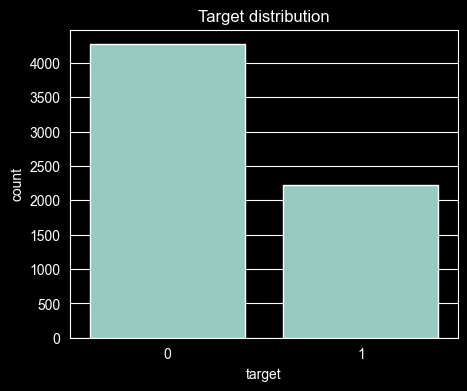

In [10]:
plt.figure(figsize=(5,4))

sns.countplot(
    data=train,
    x="target"
)

plt.title("Target distribution")
plt.show()

In [11]:
print(
    train["target"].value_counts()
)

target
0    4268
1    2220
Name: count, dtype: int64


In [12]:
train_cols = set(train.columns)
test_cols = set(test.columns)


print(
    "Только train:",
    train_cols - test_cols
)

print(
    "Только test:",
    test_cols - train_cols
)

Только train: {'target'}
Только test: set()


In [13]:
train.dtypes

application_id                   int64
client_id                        int64
employment_type                 object
hash_id                        float64
region_coefficient_extended    float64
age                            float64
incoming_amount                float64
internal_decision_code          object
monthly_income                 float64
application_date                object
education                       object
requested_product               object
channel                         object
loan_amount                    float64
marketing_segment               object
post_loan_collection_score     float64
region_coefficient             float64
region                          object
interest_rate                  float64
months_at_job                  float64
dependents                     float64
days_until_first_overdue       float64
loan_term_months               float64
siberia_northern_score         float64
target                           int64
dtype: object

In [14]:
cat_cols = train.select_dtypes(
    include=["object"]
).columns.tolist()


num_cols = train.select_dtypes(
    exclude=["object"]
).columns.tolist()


print(
    "Categorical:",
    cat_cols
)

print(
    "Numeric:",
    num_cols
)

Categorical: ['employment_type', 'internal_decision_code', 'application_date', 'education', 'requested_product', 'channel', 'marketing_segment', 'region']
Numeric: ['application_id', 'client_id', 'hash_id', 'region_coefficient_extended', 'age', 'incoming_amount', 'monthly_income', 'loan_amount', 'post_loan_collection_score', 'region_coefficient', 'interest_rate', 'months_at_job', 'dependents', 'days_until_first_overdue', 'loan_term_months', 'siberia_northern_score', 'target']


In [15]:
train.duplicated(
    subset=["application_id"]
).sum()

np.int64(8)

In [16]:
train.duplicated(
    subset=["client_id"]
).sum()

np.int64(8)

In [17]:
for col in [
    "application_id",
    "client_id",
    "hash_id"
]:

    print(
        col,
        train[col].nunique(),
        train[col].shape[0]
    )

application_id 6480 6488
client_id 6480 6488
hash_id 6064 6488


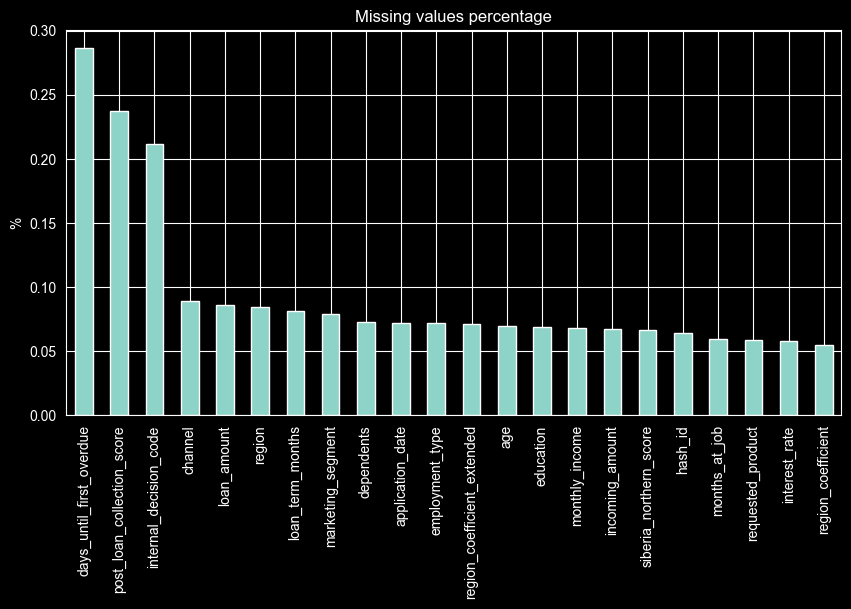

days_until_first_overdue       0.286067
post_loan_collection_score     0.237053
internal_decision_code         0.211776
channel                        0.088933
loan_amount                    0.085697
region                         0.084155
loan_term_months               0.081227
marketing_segment              0.078607
dependents                     0.072441
application_date               0.072133
employment_type                0.071671
region_coefficient_extended    0.071054
age                            0.069205
education                      0.069051
monthly_income                 0.067972
incoming_amount                0.066739
siberia_northern_score         0.066584
hash_id                        0.064273
months_at_job                  0.059494
requested_product              0.058878
interest_rate                  0.057799
region_coefficient             0.054871
dtype: float64


In [18]:
missing = (
    train.isna()
    .mean()
    .sort_values(ascending=False)
)


plt.figure(figsize=(10,5))

missing[missing > 0].plot(
    kind="bar"
)

plt.title(
    "Missing values percentage"
)

plt.ylabel("%")

plt.show()
print(missing[missing > 0])

In [19]:
for col in train.columns:

    if train[col].isna().sum() > 0:

        miss_rate = (
            train
            .groupby(
                train[col].isna()
            )["target"]
            .mean()
        )

        print("\n", col)
        print(miss_rate)


 employment_type
employment_type
False    0.342852
True     0.333333
Name: target, dtype: float64

 hash_id
hash_id
False    0.342118
True     0.342926
Name: target, dtype: float64

 region_coefficient_extended
region_coefficient_extended
False    0.344616
True     0.310195
Name: target, dtype: float64

 age
age
False    0.341778
True     0.347439
Name: target, dtype: float64

 incoming_amount
incoming_amount
False    0.341701
True     0.348730
Name: target, dtype: float64

 internal_decision_code
internal_decision_code
False    0.340829
True     0.347162
Name: target, dtype: float64

 monthly_income
monthly_income
False    0.344138
True     0.315193
Name: target, dtype: float64

 application_date
application_date
False    0.342691
True     0.335470
Name: target, dtype: float64

 education
education
False    0.340894
True     0.359375
Name: target, dtype: float64

 requested_product
requested_product
False    0.341795
True     0.348168
Name: target, dtype: float64

 channel
channel
Fa

In [20]:
corr = (
    train
    .corr(
        numeric_only=True
    )["target"]
    .sort_values()
)


print(corr)

days_until_first_overdue      -0.787820
months_at_job                 -0.246586
age                           -0.181700
incoming_amount               -0.166057
monthly_income                -0.164033
loan_term_months              -0.116021
interest_rate                 -0.080530
client_id                     -0.020555
application_id                -0.020555
siberia_northern_score        -0.003905
region_coefficient_extended    0.007221
dependents                     0.008263
hash_id                        0.018238
loan_amount                    0.159068
post_loan_collection_score     0.675753
target                         1.000000
region_coefficient                  NaN
Name: target, dtype: float64


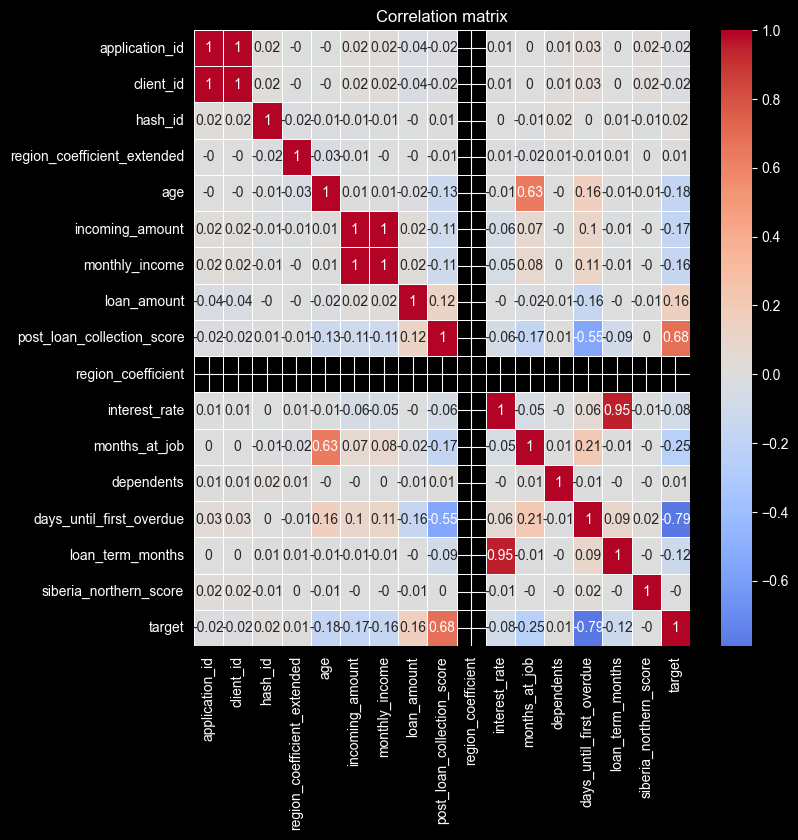

In [21]:
plt.figure(figsize=(8,8))

corr_matrix = train.corr(numeric_only=True)
corr_matrix = np.round(corr_matrix, 2)

sns.heatmap(
    corr_matrix,
    annot=True,
    linewidths=.5,
    cmap="coolwarm",
    center=0
)

plt.title('Correlation matrix')
plt.show()

In [22]:
for col in cat_cols:

    print("\n==========")
    print(col)

    print(
        train[col]
        .nunique()
    )


employment_type
5

internal_decision_code
6

application_date
365

education
4

requested_product
5

channel
5

marketing_segment
150

region
7


In [23]:
for i in ['employment_type', 'education', 'region', 'channel', 'requested_product', 'internal_decision_code']:
    print(train.groupby(
        i
    )["target"].agg(
        [
            "mean",
            "count"
        ]
    ).sort_values(
        "mean",
        ascending=False
    ))

                     mean  count
employment_type                 
unemployed       0.706294    429
contractor       0.440000    825
self_employed    0.310875    846
employee         0.294806   3331
business         0.260135    592
               mean  count
education                 
master     0.349490    784
college    0.348580   1902
bachelor   0.335018   2176
school     0.333616   1178
             mean  count
region                  
siberia  0.372679    754
center   0.362660   1489
north    0.353285    685
south    0.327910    799
ural     0.325301    581
west     0.317671    979
east     0.294656    655
                 mean  count
channel                     
partner      0.363063   1110
web          0.341361   1661
office       0.338547    895
mobile       0.336538   1768
call_center  0.324948    477
                       mean  count
requested_product                 
cash               0.406142   2312
refinance          0.317673    894
card               0.305171   1373
auto

In [24]:
train["application_date"] = pd.to_datetime(
    train["application_date"]
)

In [25]:
train["application_year"] = (
    train["application_date"]
    .dt.year
)


train["application_month"] = (
    train["application_date"]
    .dt.month
)

In [26]:
print(train.groupby(
    "application_month"
)["target"].mean())

application_month
1.0     0.351562
2.0     0.324895
3.0     0.354898
4.0     0.326360
5.0     0.350674
6.0     0.319527
7.0     0.359026
8.0     0.341176
9.0     0.355932
10.0    0.344358
11.0    0.316770
12.0    0.363636
Name: target, dtype: float64


In [27]:
train_clients = set(
    train.client_id
)

transaction_clients = set(
    transactions.client_id
)


coverage = (
    len(
        train_clients &
        transaction_clients
    )
    /
    len(train_clients)
)


coverage

1.0

In [28]:
for name, df in [
    ("bureau", bureau),
    ("previous_loans", previous_loans)
]:

    coverage = (
        train.client_id
        .isin(
            df.client_id
        )
        .mean()
    )

    print(
        name,
        coverage
    )

bureau 0.9480579531442663
previous_loans 0.7672626387176326


In [29]:
print(train[
    [
        "days_until_first_overdue",
        "target"
    ]
].groupby(
    "target"
).describe())

       days_until_first_overdue                                              \
                          count        mean         std   min    25%    50%   
target                                                                        
0                        3048.0  828.099738  314.847137  30.0  730.0  999.0   
1                        1584.0  102.695707  144.773300   1.0   42.0   80.5   

                         
            75%     max  
target                   
0       1000.00  1002.0  
1        119.25   999.0  


In [30]:
print(train.groupby(
    "target"
)[
    "post_loan_collection_score"
].mean())

target
0    379.679635
1    699.618124
Name: post_loan_collection_score, dtype: float64


In [31]:
DROP_ALWAYS = [
    "target",
    "application_id",
    "days_until_first_overdue",
    "post_loan_collection_score",
    "internal_decision_code"
]

### Feature Engineering train test

In [32]:
train_fe = train.copy()
test_fe = test.copy()

In [33]:
def create_base_features(df):

    df = df.copy()

    # Date features
    df["application_date"] = pd.to_datetime(
        df["application_date"]
    )

    df["application_year"] = (
        df["application_date"].dt.year
    )

    df["application_month"] = (
        df["application_date"].dt.month
    )

    df["application_day"] = (
        df["application_date"].dt.day
    )

    df["application_weekday"] = (
        df["application_date"].dt.weekday
    )

    df["application_dayofyear"] = (
        df["application_date"].dt.dayofyear
    )


    # Ratios
    df["loan_to_income"] = (
        df["loan_amount"] /
        (df["monthly_income"] + 1)
    )

    df["loan_to_incoming"] = (
        df["loan_amount"] /
        (df["incoming_amount"] + 1)
    )

    df["income_per_dependent"] = (
        df["monthly_income"] /
        (df["dependents"] + 1)
    )

    df["incoming_minus_loan"] = (
        df["incoming_amount"]
        -
        df["loan_amount"]
    )


    # Employment stability
    df["job_age_ratio"] = (
        df["months_at_job"] /
        ((df["age"] * 12) + 1)
    )


    # Age groups
    df["young_client"] = (
        df["age"] < 25
    ).astype(int)

    df["older_client"] = (
        df["age"] > 55
    ).astype(int)


    # Loan term
    df["long_term_loan"] = (
        df["loan_term_months"] >= 24
    ).astype(int)

    df["short_term_loan"] = (
        df["loan_term_months"] <= 6
    ).astype(int)


    # Interest
    df["high_interest"] = (
        df["interest_rate"] >
        df["interest_rate"].median()
    ).astype(int)


    # Missing count
    df["missing_count"] = (
        df.isna().sum(axis=1)
    )


    # Drop unavailable / leakage features
    df = df.drop(
        columns=[
            "application_date",
            "application_id",
            "days_until_first_overdue",
            "post_loan_collection_score",
            "internal_decision_code"
        ],
        errors="ignore"
    )

    return df

In [34]:
train_fe = create_base_features(train)
test_fe = create_base_features(test)

In [35]:
print(train_fe.shape)
print(test_fe.shape)

train_fe.head()

train_fe.dtypes

print(train_fe.isna().mean().sort_values(
    ascending=False
).head(15))

(6488, 36)
(2520, 35)
loan_to_income          0.148274
loan_to_incoming        0.146732
incoming_minus_loan     0.146732
income_per_dependent    0.136252
job_age_ratio           0.125771
channel                 0.088933
loan_amount             0.085697
region                  0.084155
loan_term_months        0.081227
marketing_segment       0.078607
dependents              0.072441
application_day         0.072133
application_year        0.072133
application_weekday     0.072133
application_month       0.072133
dtype: float64


In [36]:
set(train_fe.columns) - set(test_fe.columns)

{'target'}

In [37]:
set(test_fe.columns) - set(train_fe.columns)

set()

In [38]:
print("TRAIN ONLY")
print(
    sorted(
        list(
            set(train_fe.columns)
            -
            set(test_fe.columns)
        )
    )
)

print("\nTEST ONLY")
print(
    sorted(
        list(
            set(test_fe.columns)
            -
            set(train_fe.columns)
        )
    )
)

TRAIN ONLY
['target']

TEST ONLY
[]


### FE for transactions

In [39]:
print(transactions.shape)

print(
    transactions["client_id"].nunique()
)

print(
    train["client_id"].nunique()
)

print(
    test["client_id"].nunique()
)

(353300, 6)
9000
6480
2520


In [40]:
transactions_fe = transactions.copy()

In [41]:
transactions_fe["transaction_date"] = pd.to_datetime(
    transactions_fe["transaction_date"]
)

In [42]:
transactions_fe["transaction_month"] = (
    transactions_fe["transaction_date"]
    .dt.month
)

transactions_fe["transaction_year"] = (
    transactions_fe["transaction_date"]
    .dt.year
)

transactions_fe["transaction_weekday"] = (
    transactions_fe["transaction_date"]
    .dt.weekday
)

In [43]:
transactions_fe["income_amount"] = (
    transactions_fe["amount"]
    .clip(lower=0)
)

transactions_fe["expense_amount"] = (
    -transactions_fe["amount"]
    .clip(lower=0)
)

In [44]:
transaction_agg = (
    transactions_fe
    .groupby("client_id")
    .agg(
        transaction_count=(
            "amount",
            "count"
        ),

        transaction_total=(
            "amount",
            "sum"
        ),

        transaction_mean=(
            "amount",
            "mean"
        ),

        transaction_std=(
            "amount",
            "std"
        ),

        income_total=(
            "income_amount",
            "sum"
        ),

        expense_total=(
            "expense_amount",
            "sum"
        ),

        amount_max=(
            "amount",
            "max"
        ),

        amount_min=(
            "amount",
            "min"
        ),

        merchant_risk_mean=(
            "merchant_risk_level",
            "mean"
        ),

        merchant_risk_max=(
            "merchant_risk_level",
            "max"
        )
    )
    .reset_index()
)

In [45]:
transaction_agg[
    "transaction_balance"
] = (
    transaction_agg["income_total"]
    -
    transaction_agg["expense_total"]
)

In [46]:
transaction_agg[
    "expense_ratio"
] = (
    transaction_agg["expense_total"]
    /
    (transaction_agg["income_total"] + 1)
)

In [47]:
print(transactions["transaction_category"].value_counts())

transaction_category
groceries          80455
transfer           50401
cash_withdrawal    50080
salary             39850
entertainment      33996
loan_payment       33703
utilities          33621
gambling           13493
Name: count, dtype: int64


In [48]:
category_count = (
    pd.crosstab(
        transactions_fe["client_id"],
        transactions_fe["transaction_category"]
    )
)

category_count.columns = [
    f"count_{c}"
    for c in category_count.columns
]

In [49]:
category_sum = (
    transactions_fe
    .pivot_table(
        index="client_id",
        columns="transaction_category",
        values="amount",
        aggfunc="sum",
        fill_value=0
    )
)

category_sum.columns = [
    f"sum_{c}"
    for c in category_sum.columns
]

In [50]:
transaction_features = (
    transaction_agg
    .merge(
        category_count,
        on="client_id",
        how="left"
    )
    .merge(
        category_sum,
        on="client_id",
        how="left"
    )
)

In [51]:
transaction_features.shape

(9000, 29)

In [52]:
train_fe = train_fe.merge(
    transaction_features,
    on="client_id",
    how="left"
)

test_fe = test_fe.merge(
    transaction_features,
    on="client_id",
    how="left"
)

In [53]:
print(train_fe.shape)
print(test_fe.shape)

(6488, 64)
(2520, 63)


In [54]:
print(train_fe.filter(
    like="transaction"
).head())

   transaction_count  transaction_total  transaction_mean  transaction_std  \
0                 36          -67211.14      -1866.976111      2905.830701   
1                 27          -35156.07      -1302.076667      4995.040491   
2                 26          -33283.41      -1280.131154      1660.385556   
3                 40           69935.52       1748.388000     10474.233444   
4                 34          -35688.58      -1049.664118      1427.844317   

   transaction_balance  
0             29873.36  
1             54494.70  
2              7902.78  
3            266323.74  
4              6515.40  


### FE for bureau

In [55]:
print(bureau["account_type"].value_counts(dropna=False))

account_type
credit_card    8051
consumer       7486
microloan      3622
auto           2546
mortgage       2147
NaN             837
Name: count, dtype: int64


In [56]:
print(bureau["bureau_status"].value_counts(dropna=False))

bureau_status
active    16019
closed     7395
NaN        1275
Name: count, dtype: int64


In [57]:
bureau_fe = bureau.copy()

In [58]:
bureau_agg = (
    bureau_fe
    .groupby("client_id")
    .agg(
        bureau_accounts_count=(
            "bureau_account_id",
            "count"
        ),

        credit_limit_total=(
            "credit_limit",
            "sum"
        ),

        credit_limit_mean=(
            "credit_limit",
            "mean"
        ),

        current_balance_total=(
            "current_balance",
            "sum"
        ),

        current_balance_mean=(
            "current_balance",
            "mean"
        ),

        max_dpd_max=(
            "max_dpd_last_12m",
            "max"
        ),

        max_dpd_mean=(
            "max_dpd_last_12m",
            "mean"
        ),

        opened_days_min=(
            "opened_days_ago",
            "min"
        ),

        opened_days_mean=(
            "opened_days_ago",
            "mean"
        )
    )
    .reset_index()
)

In [59]:
bureau_agg["credit_utilization"] = (
    bureau_agg["current_balance_total"]
    /
    (bureau_agg["credit_limit_total"] + 1)
)

In [60]:
bureau_bad = (
    bureau_fe
    .assign(
        has_dpd=
        (
            bureau_fe["max_dpd_last_12m"] > 0
        ).astype(int)
    )
    .groupby("client_id")
    ["has_dpd"]
    .agg(
        bureau_accounts_with_dpd="sum",
        bureau_dpd_ratio="mean"
    )
    .reset_index()
)

In [61]:
bureau_type_count = pd.crosstab(
    bureau_fe["client_id"],
    bureau_fe["account_type"]
)

bureau_type_count.columns = [
    f"bureau_count_{c}"
    for c in bureau_type_count.columns
]

In [62]:
bureau_status_count = pd.crosstab(
    bureau_fe["client_id"],
    bureau_fe["bureau_status"]
)

bureau_status_count.columns = [
    f"bureau_status_{c}"
    for c in bureau_status_count.columns
]

In [63]:
bureau_features = (
    bureau_agg
    .merge(
        bureau_bad,
        on="client_id",
        how="left"
    )
    .merge(
        bureau_type_count,
        on="client_id",
        how="left"
    )
    .merge(
        bureau_status_count,
        on="client_id",
        how="left"
    )
)

In [64]:
train_fe = train_fe.merge(
    bureau_features,
    on="client_id",
    how="left"
)

test_fe = test_fe.merge(
    bureau_features,
    on="client_id",
    how="left"
)

In [65]:
bureau_features.shape

(8542, 20)

In [66]:
display(train_fe.shape,test_fe.shape)

(6488, 83)

(2520, 82)

In [67]:
print(train_fe.filter(like="bureau").describe())

       bureau_accounts_count  bureau_accounts_with_dpd  bureau_dpd_ratio  \
count            6151.000000               6151.000000       6151.000000   
mean                2.897090                  1.456836          0.499273   
std                 1.483999                  1.144537          0.339046   
min                 1.000000                  0.000000          0.000000   
25%                 2.000000                  1.000000          0.250000   
50%                 3.000000                  1.000000          0.500000   
75%                 4.000000                  2.000000          0.750000   
max                10.000000                  7.000000          1.000000   

       bureau_count_auto  bureau_count_consumer  bureau_count_credit_card  \
count        6106.000000            6106.000000               6106.000000   
mean            0.298886               0.886014                  0.952670   
std             0.541108               0.912437                  0.926745   
min    

In [68]:
train_fe["has_bureau"] = (
    train_fe["bureau_accounts_count"]
    .notna()
).astype(int)

test_fe["has_bureau"] = (
    test_fe["bureau_accounts_count"]
    .notna()
).astype(int)

In [69]:
for df in [train_fe, test_fe]:

    df["bureau_active_ratio"] = (
        df["bureau_status_active"]
        /
        (df["bureau_accounts_count"] + 1)
    )

In [70]:
for df in [train_fe, test_fe]:

    df["bureau_balance_per_credit"] = (
        df["current_balance_total"]
        /
        (df["bureau_accounts_count"] + 1)
    )

In [71]:
for df in [train_fe, test_fe]:

    df["bureau_severe_dpd"] = (
        df["max_dpd_max"] > 30
    ).astype(int)

### FE for previous loans

In [72]:
previous_loans.shape

(12762, 7)

In [73]:
previous_loans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12762 entries, 0 to 12761
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   client_id             12762 non-null  int64  
 1   previous_loan_id      12762 non-null  object 
 2   previous_amount       12445 non-null  float64
 3   previous_term_months  12117 non-null  float64
 4   closed_days_ago       12246 non-null  float64
 5   was_overdue           12496 non-null  float64
 6   max_overdue_days      12318 non-null  float64
dtypes: float64(5), int64(1), object(1)
memory usage: 698.1+ KB


In [74]:
print(previous_loans["was_overdue"].value_counts(dropna=False))

was_overdue
0.0    9802
1.0    2694
NaN     266
Name: count, dtype: int64


In [75]:
print(previous_loans.describe())

          client_id  previous_amount  previous_term_months  closed_days_ago  \
count  12762.000000     12445.000000          12117.000000     12246.000000   
mean    4512.050306     56621.215050             15.324090       813.172709   
std     2598.207487     33839.413872             10.647548       457.405745   
min        2.000000      6101.880000              3.000000        20.000000   
25%     2232.000000     33506.610000              6.000000       417.000000   
50%     4545.500000     48665.570000             12.000000       813.500000   
75%     6739.750000     70704.430000             24.000000      1215.000000   
max     9000.000000    527095.240000             36.000000      1599.000000   

        was_overdue  max_overdue_days  
count  12496.000000      12318.000000  
mean       0.215589          3.866131  
std        0.411247         12.819714  
min        0.000000          0.000000  
25%        0.000000          0.000000  
50%        0.000000          0.000000  
75%     

In [76]:
previous_loans_fe = previous_loans.copy()

In [77]:
previous_agg = (
    previous_loans_fe
    .groupby("client_id")
    .agg(
        previous_loans_count=(
            "previous_loan_id",
            "count"
        ),

        previous_amount_sum=(
            "previous_amount",
            "sum"
        ),

        previous_amount_mean=(
            "previous_amount",
            "mean"
        ),

        previous_amount_max=(
            "previous_amount",
            "max"
        ),

        previous_term_mean=(
            "previous_term_months",
            "mean"
        ),

        previous_term_max=(
            "previous_term_months",
            "max"
        ),

        closed_days_mean=(
            "closed_days_ago",
            "mean"
        ),

        closed_days_min=(
            "closed_days_ago",
            "min"
        ),

        max_overdue_days_max=(
            "max_overdue_days",
            "max"
        ),

        max_overdue_days_mean=(
            "max_overdue_days",
            "mean"
        )
    )
    .reset_index()
)

In [78]:
previous_overdue = (
    previous_loans_fe
    .assign(
        overdue_flag=
        previous_loans_fe["was_overdue"]
        .fillna(0)
    )
    .groupby("client_id")
    .agg(
        previous_overdue_count=(
            "overdue_flag",
            "sum"
        ),

        previous_overdue_ratio=(
            "overdue_flag",
            "mean"
        )
    )
    .reset_index()
)

In [79]:
previous_loans_fe["severe_overdue"] = (
    previous_loans_fe["max_overdue_days"]
    >= 30
).astype(int)

In [80]:
previous_severe = (
    previous_loans_fe
    .groupby("client_id")
    .agg(
        severe_overdue_count=(
            "severe_overdue",
            "sum"
        )
    )
    .reset_index()
)

In [81]:
previous_agg["loan_frequency"] = (
    previous_agg["previous_loans_count"]
    /
    (
        previous_agg["closed_days_min"]
        / 365
        + 1
    )
)

In [82]:
previous_features = (
    previous_agg
    .merge(
        previous_overdue,
        on="client_id",
        how="left"
    )
    .merge(
        previous_severe,
        on="client_id",
        how="left"
    )
)

In [83]:
previous_features.shape

(6885, 15)

In [84]:
train_fe = train_fe.merge(
    previous_features,
    on="client_id",
    how="left"
)


test_fe = test_fe.merge(
    previous_features,
    on="client_id",
    how="left"
)

In [85]:
for df in [train_fe, test_fe]:

    df["has_previous_loans"] = (
        df["previous_loans_count"]
        .notna()
    ).astype(int)

In [86]:
display(train_fe.shape,test_fe.shape)

(6488, 102)

(2520, 101)

In [87]:
print(train_fe.filter(
    like="previous"
).describe())

       previous_loans_count  previous_amount_sum  previous_amount_mean  \
count           4978.000000          4978.000000           4916.000000   
mean               1.840297        101467.380068          56531.784467   
std                0.993048         73232.669497          28296.975052   
min                1.000000             0.000000           6992.890000   
25%                1.000000         48137.220000          37749.456667   
50%                2.000000         83909.205000          50774.376667   
75%                2.000000        135612.217500          68732.615000   
max                7.000000        670392.520000         294685.420000   

       previous_amount_max  previous_term_mean  previous_term_max  \
count          4916.000000         4846.000000        4846.000000   
mean          68243.805271           15.282489          19.126083   
std           38020.319690            9.013884          11.157767   
min            6992.890000            3.000000           

In [88]:
print(train_fe.isna().mean().sort_values(
    ascending=False
).head(20))

previous_term_mean        0.253083
previous_term_max         0.253083
closed_days_min           0.248305
closed_days_mean          0.248305
loan_frequency            0.248305
max_overdue_days_max      0.247996
max_overdue_days_mean     0.247996
previous_amount_mean      0.242293
previous_amount_max       0.242293
previous_overdue_count    0.232737
previous_overdue_ratio    0.232737
severe_overdue_count      0.232737
previous_loans_count      0.232737
previous_amount_sum       0.232737
loan_to_income            0.148274
loan_to_incoming          0.146732
incoming_minus_loan       0.146732
income_per_dependent      0.136252
job_age_ratio             0.125771
channel                   0.088933
dtype: float64


In [89]:
set(train_fe.columns) - set(test_fe.columns)

{'target'}

In [90]:
display(train_fe.shape, test_fe.shape)

(6488, 102)

(2520, 101)

In [91]:
print(train_fe["target"].value_counts(normalize=True))

target
0    0.65783
1    0.34217
Name: proportion, dtype: float64


In [92]:
print(train_fe.dtypes.value_counts())

float64    76
int64      20
object      6
Name: count, dtype: int64


In [93]:
train_fe.select_dtypes(
    include="object"
).columns.tolist()

['employment_type',
 'education',
 'requested_product',
 'channel',
 'marketing_segment',
 'region']

In [94]:
train_fe.select_dtypes(
    exclude="object"
).columns.tolist()

['client_id',
 'hash_id',
 'region_coefficient_extended',
 'age',
 'incoming_amount',
 'monthly_income',
 'loan_amount',
 'region_coefficient',
 'interest_rate',
 'months_at_job',
 'dependents',
 'loan_term_months',
 'siberia_northern_score',
 'target',
 'application_year',
 'application_month',
 'application_day',
 'application_weekday',
 'application_dayofyear',
 'loan_to_income',
 'loan_to_incoming',
 'income_per_dependent',
 'incoming_minus_loan',
 'job_age_ratio',
 'young_client',
 'older_client',
 'long_term_loan',
 'short_term_loan',
 'high_interest',
 'missing_count',
 'transaction_count',
 'transaction_total',
 'transaction_mean',
 'transaction_std',
 'income_total',
 'expense_total',
 'amount_max',
 'amount_min',
 'merchant_risk_mean',
 'merchant_risk_max',
 'transaction_balance',
 'expense_ratio',
 'count_cash_withdrawal',
 'count_entertainment',
 'count_gambling',
 'count_groceries',
 'count_loan_payment',
 'count_salary',
 'count_transfer',
 'count_utilities',
 'sum_cash_w

In [95]:
train_fe.duplicated().sum()

np.int64(8)

In [96]:
train["client_id"].nunique(), train.shape[0]

(6480, 6488)

In [97]:
test["client_id"].nunique(), test.shape[0]

(2520, 2520)

In [98]:
duplicates = (
    train
    [train["client_id"].duplicated(
        keep=False
    )]
    .sort_values("client_id")
)

duplicates[
    [
        "client_id",
        "target"
    ]
]

,client_id,target
5109,1549,0
6481,1549,0
6483,1662,1
4750,1662,1
1895,2303,0
6486,2303,0
6484,3037,1
6462,3037,1
6487,3952,0
4667,3952,0


In [99]:
train_fe = (
    train_fe
    .sort_values("client_id")
    .drop_duplicates(
        subset="client_id",
        keep="first"
    )
)

In [100]:
display(train_fe.shape, test_fe.shape)

(6480, 102)

(2520, 101)

### Baseline CatBoost

In [101]:
X_catboost = train_fe.drop(
    columns=["target"]
).copy()

y = train_fe["target"].copy()

X_test_catboost = test_fe.copy()

In [102]:
cat_features = (
    X_catboost
    .select_dtypes(
        include="object"
    )
    .columns
    .tolist()
)

cat_features

['employment_type',
 'education',
 'requested_product',
 'channel',
 'marketing_segment',
 'region']

In [103]:
for col in cat_features:

    X_catboost[col] = (
        X_catboost[col]
        .fillna("missing")
        .astype(str)
    )

    X_test_catboost[col] = (
        X_test_catboost[col]
        .fillna("missing")
        .astype(str)
    )

In [104]:
X_test_catboost = X_test_catboost[
    X_catboost.columns
]
print(
    "Categorical features:",
    cat_features
)

Categorical features: ['employment_type', 'education', 'requested_product', 'channel', 'marketing_segment', 'region']


In [105]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [106]:
param_grid = {

    "depth": [
        4,
        5,
        6,
        7,
        8,
        9,
        10
    ],

    "learning_rate": [
        0.005,
        0.01,
        0.02,
        0.03,
        0.05,
        0.07,
        0.1
    ],

    "l2_leaf_reg": [
        1,
        3,
        5,
        10,
        20,
        50,
        100
    ],

    "random_strength": [
        0,
        0.5,
        1,
        2,
        5,
        10
    ],

    "border_count": [
        32,
        64,
        128,
        254
    ],

    "bootstrap_type": [
        "Bayesian",
        "Bernoulli"
    ],

    "bagging_temperature": [
        0,
        0.5,
        1,
        3,
        5,
        10
    ],

    "subsample": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "auto_class_weights": [
        "Balanced",
        None
    ]
}


all_params = list(
    itertools.product(
        *param_grid.values()
    )
)


np.random.seed(42)


n_trials = 500


selected_params = np.random.choice(
    len(all_params),
    size=n_trials,
    replace=False
)


param_names = list(
    param_grid.keys()
)


experiments = []


for idx in selected_params:

    values = all_params[idx]

    params = dict(
        zip(
            param_names,
            values
        )
    )


    # Исправление несовместимых параметров
    if params["bootstrap_type"] != "Bayesian":

        params["bagging_temperature"] = None


    if params["bootstrap_type"] == "Bayesian":

        params["subsample"] = None


    experiments.append(
        params
    )


print(
    "Количество экспериментов:",
    len(experiments)
)

Количество экспериментов: 500


In [107]:
X_train_search, X_valid_search, y_train_search, y_valid_search = train_test_split(
    X_catboost,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [108]:
results = []

best_auc = 0
best_params = None


for i, params in enumerate(experiments,1):

    print(
        "\n===================="
    )

    print(
        f"Experiment {i}/{n_trials}"
    )

    print(
        params
    )


    model = CatBoostClassifier(

        **{
            k:v for k,v in params.items()
            if v is not None
        },

        loss_function="Logloss",

        eval_metric="AUC",

        random_seed=42,

        verbose=0,

        task_type="CPU",

        thread_count=-1

    )

    model.fit(

        X_train_search,

        y_train_search,

        eval_set=(
            X_valid_search,
            y_valid_search
        ),

        cat_features=cat_features,

        early_stopping_rounds=100,

        verbose=0

    )


    pred = model.predict_proba(
        X_valid_search
    )[:,1]


    auc = roc_auc_score(
        y_valid_search,
        pred
    )


    print(
        "AUC:",
        auc
    )


    results.append({

        **params,

        "auc": auc

    })


    if auc > best_auc:

        best_auc = auc

        best_params = params.copy()

        print(
            "NEW BEST"
        )


print(
    "\n===================="
)

print(
    "BEST AUC:",
    best_auc
)

print(
    "BEST PARAMETERS:"
)

print(
    best_params
)



Experiment 1/500
{'depth': 6, 'learning_rate': 0.07, 'l2_leaf_reg': 3, 'random_strength': 2, 'border_count': 64, 'bootstrap_type': 'Bernoulli', 'bagging_temperature': None, 'subsample': 0.8, 'auto_class_weights': None}
AUC: 0.8213874085352958
NEW BEST

Experiment 2/500
{'depth': 8, 'learning_rate': 0.05, 'l2_leaf_reg': 5, 'random_strength': 5, 'border_count': 128, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 10, 'subsample': None, 'auto_class_weights': None}
AUC: 0.8029252844393688

Experiment 3/500
{'depth': 4, 'learning_rate': 0.07, 'l2_leaf_reg': 20, 'random_strength': 1, 'border_count': 32, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 5, 'subsample': None, 'auto_class_weights': None}
AUC: 0.8171155310239818

Experiment 4/500
{'depth': 4, 'learning_rate': 0.1, 'l2_leaf_reg': 3, 'random_strength': 0.5, 'border_count': 64, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 3, 'subsample': None, 'auto_class_weights': None}
AUC: 0.8195343230554498

Experiment 5/500
{'

In [109]:
results_df = pd.DataFrame(
    results
)


results_df = results_df.sort_values(
    "auc",
    ascending=False
)


results_df.to_csv(
    "catboost_huge_search_results.csv",
    index=False
)


print(
    results_df.head(20)
)

     depth  learning_rate  l2_leaf_reg  random_strength  border_count  \
239      7           0.05            5              0.5            32   
222      6           0.02           20              0.5            32   
43       4           0.07            1              2.0            32   
479      9           0.10          100              1.0           128   
237      5           0.05            3              1.0           254   
425      6           0.03            5             10.0            32   
292      8           0.05            3              0.5            32   
242      8           0.05          100              1.0            32   
364      9           0.02          100              0.5            64   
86       8           0.05           20              0.5            32   
45       5           0.10           50              1.0            32   
85       8           0.07          100              1.0           254   
48       7           0.05          100             

### Result

In [110]:
final_params = {
    k: v
    for k, v in best_params.items()
    if v is not None
}


final_catboost = CatBoostClassifier(

    **final_params,

    loss_function="Logloss",

    eval_metric="AUC",

    random_seed=42,

    verbose=100,

    task_type="CPU",

    thread_count=-1

)


final_catboost.fit(

    X_catboost,

    y,

    cat_features=cat_features

)

0:	total: 17.6ms	remaining: 17.6s
100:	total: 3.34s	remaining: 29.7s
200:	total: 9.28s	remaining: 36.9s
300:	total: 12.8s	remaining: 29.6s
400:	total: 14.7s	remaining: 22s
500:	total: 17.6s	remaining: 17.5s
600:	total: 19.6s	remaining: 13s
700:	total: 21.5s	remaining: 9.16s
800:	total: 23.5s	remaining: 5.83s
900:	total: 25.4s	remaining: 2.8s
999:	total: 27.4s	remaining: 0us


CatBoostClassifier(bagging_temperature=1, bootstrap_type='Bayesian', border_count=32, depth=7, eval_metric='AUC', l2_leaf_reg=5, learning_rate=0.05, loss_function='Logloss', random_seed=42, random_strength=0.5, task_type='CPU', verbose=100)

In [111]:
importance = pd.DataFrame({

    "feature":
        X_catboost.columns,

    "importance":
        final_catboost.feature_importances_

})


importance = importance.sort_values(
    "importance",
    ascending=False
)


print(
    importance.head(30)
)


importance.to_csv(
    "catboost_feature_importance.csv",
    index=False
)


                   feature  importance
15           months_at_job    4.548653
68             max_dpd_max    3.811222
4                      age    2.525169
14           interest_rate    2.370032
8        requested_product    2.366019
1          employment_type    2.324128
28           job_age_ratio    2.302173
27     incoming_minus_loan    2.210019
43      merchant_risk_mean    2.167234
72      credit_utilization    2.089213
17        loan_term_months    2.050583
69            max_dpd_mean    1.980277
2                  hash_id    1.950555
85       bureau_severe_dpd    1.876858
18  siberia_northern_score    1.806784
0                client_id    1.784723
10             loan_amount    1.628284
21         application_day    1.603921
25        loan_to_incoming    1.596603
70         opened_days_min    1.518260
55     sum_cash_withdrawal    1.493908
24          loan_to_income    1.493729
35       transaction_count    1.434171
56       sum_entertainment    1.394717
71        opened_days_mea

In [112]:
test_pred = final_catboost.predict_proba(
    X_test_catboost
)[:,1]

In [113]:
submission = pd.DataFrame({

    "application_id":
        test["application_id"],

    "target":
        test_pred

})

### Export

In [114]:
submission.to_csv(
    "submission.csv",
    index=False
)

In [115]:
!pip freeze > requirements.txt
with zipfile.ZipFile("submission.zip", "w", zipfile.ZIP_DEFLATED) as zipf:
    zipf.write("submission.csv")
    zipf.write("competition.ipynb")
    zipf.write("requirements.txt")